,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


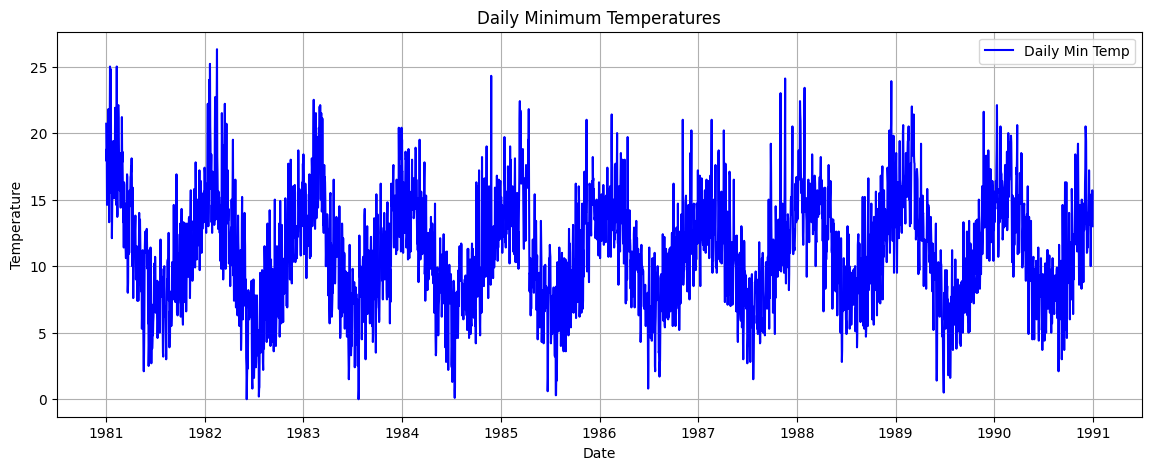

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the daily minimum temperatures dataset
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
temp_data = pd.read_csv(url)

# Prepare the data
temp_data['Date'] = pd.to_datetime(temp_data['Date'])
temp_data = temp_data.sort_values('Date')
temp_data = temp_data.set_index('Date')

# Display the first few rows
display(temp_data.head())

# Plot the raw temperature data
plt.figure(figsize=(14, 5))
plt.plot(temp_data['Temp'], color='blue', label='Daily Min Temp')
plt.title('Daily Minimum Temperatures')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.grid(True)
plt.show()

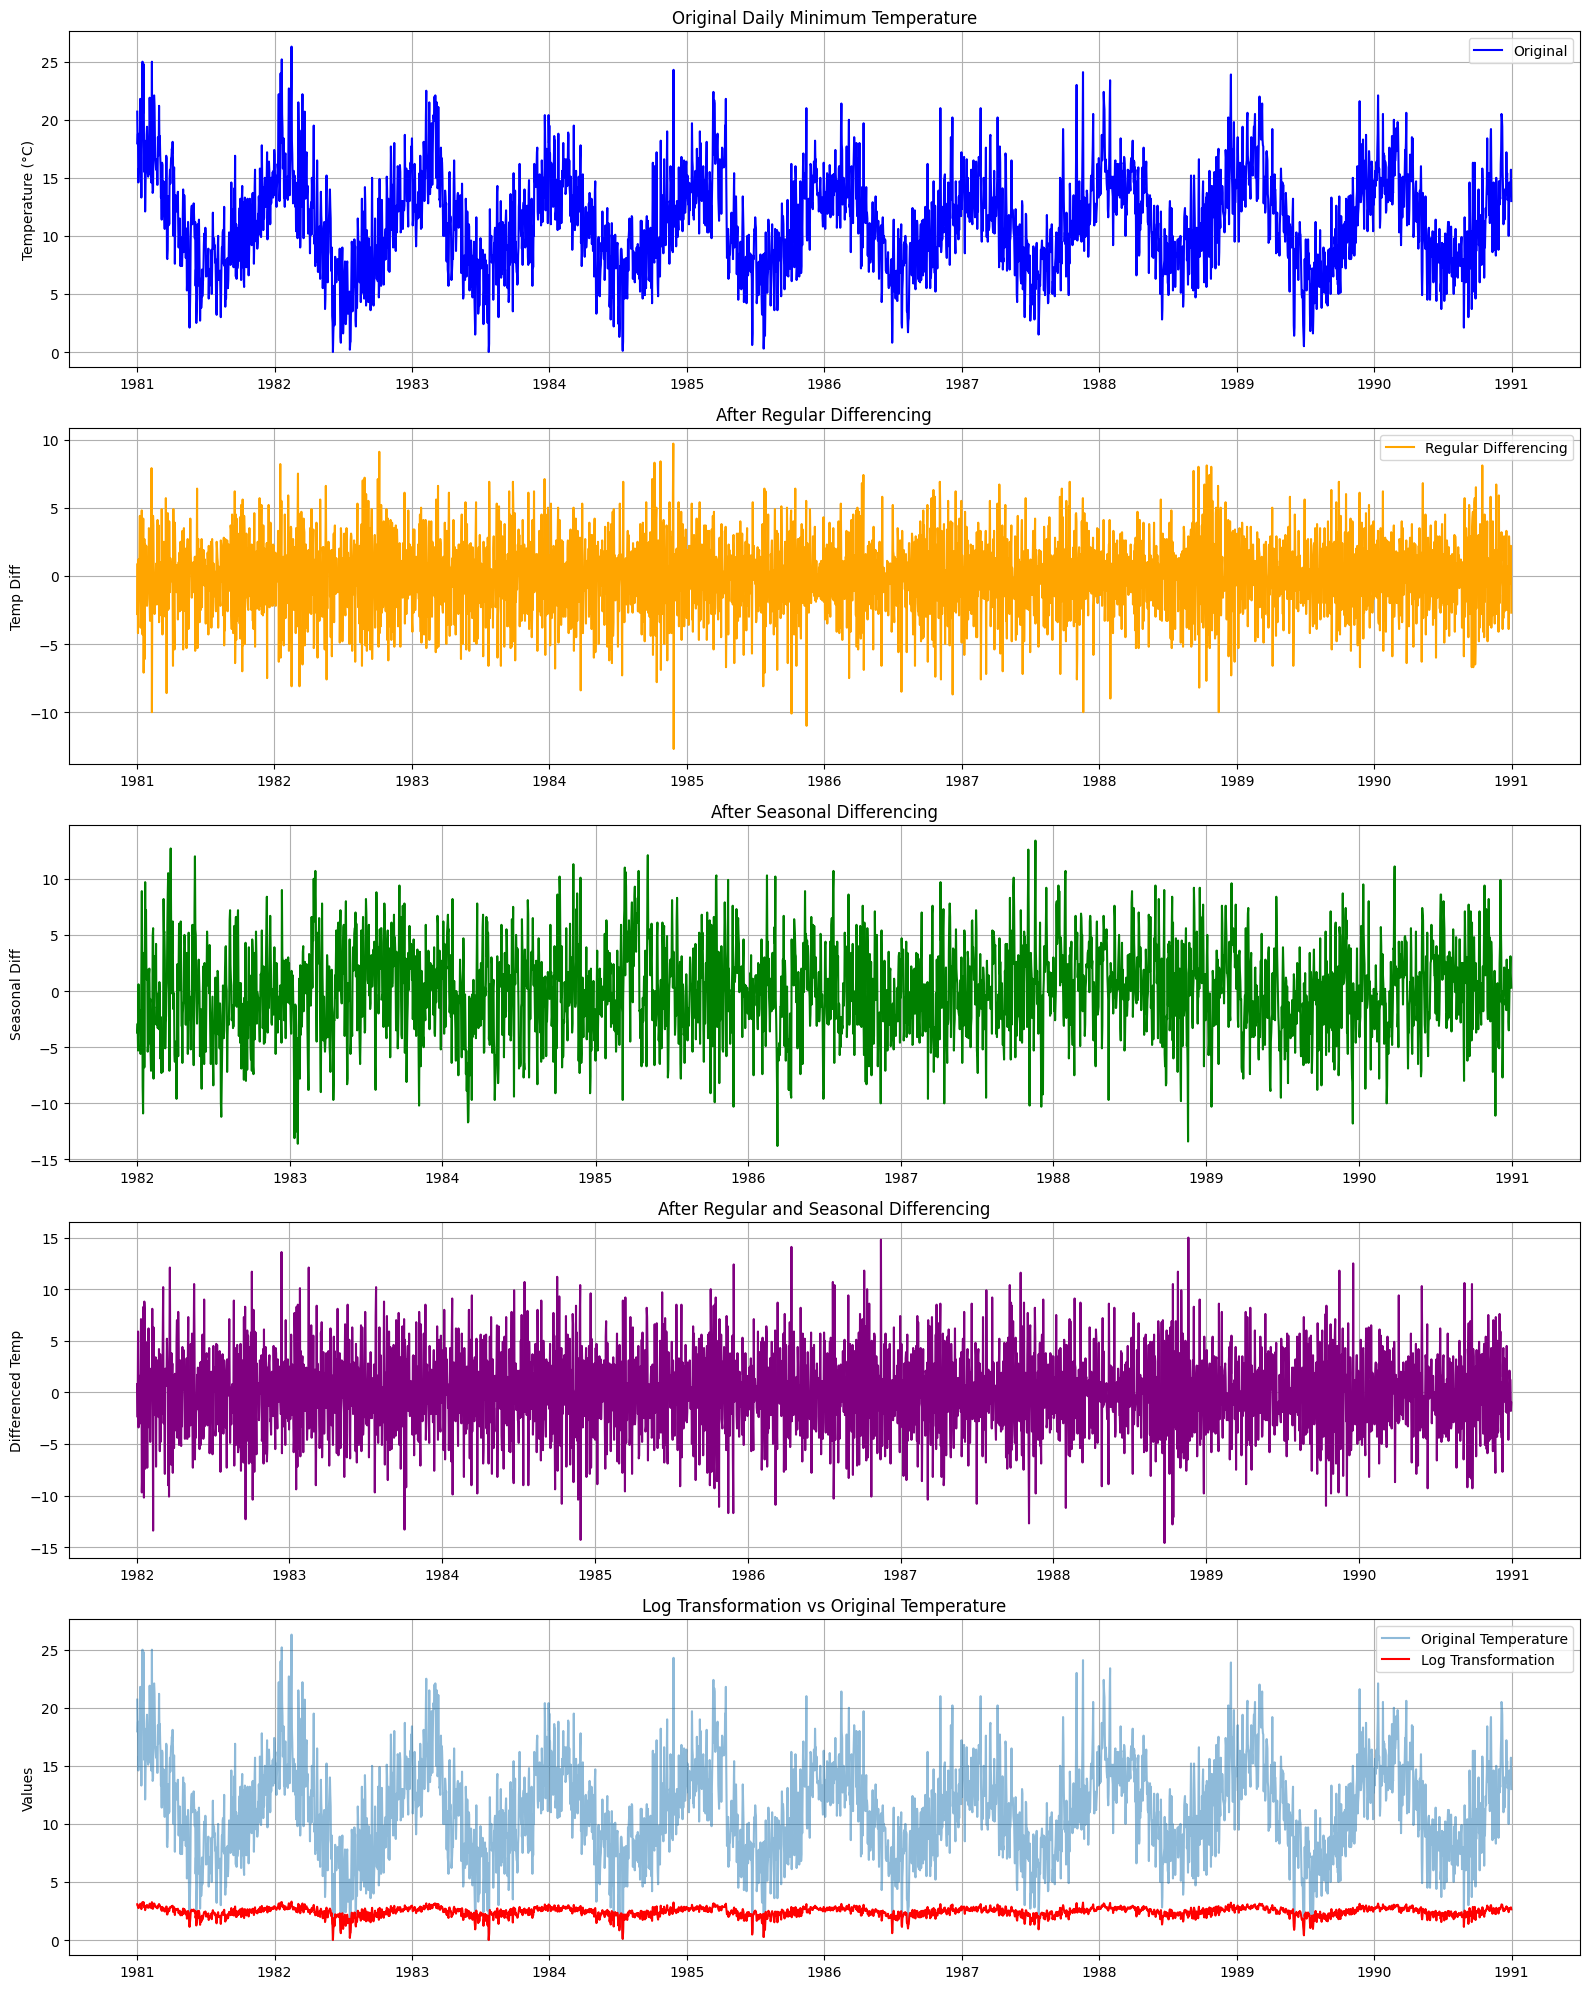

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load and process the data once
data = pd.read_csv(
    'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
)
data['Date'] = pd.to_datetime(data['Date'])
data = data.sort_values('Date')
data = data.set_index('Date')

data['Temp'] = pd.to_numeric(data['Temp'], errors='coerce')
data = data.dropna(subset=['Temp'])

# 2. Compute transformations
data['temp_diff'] = data['Temp'].diff()

period = 365
data['temp_seasonal_diff'] = data['Temp'].diff(period)
data['temp_regular_seasonal_diff'] = (
    data['Temp'].diff().diff(period)
)
data['temp_log'] = np.log1p(data['Temp'])

# 3. Visualizations
plt.figure(figsize=(16, 20))

# Plot 1: Original Series
plt.subplot(5, 1, 1)
plt.plot(data['Temp'], label='Original', color='blue')
plt.title('Original Daily Minimum Temperature')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.legend()

# Plot 2: Regular Differencing
plt.subplot(5, 1, 2)
plt.plot(data['temp_diff'], label='Regular Differencing', color='orange')
plt.title('After Regular Differencing')
plt.ylabel('Temp Diff')
plt.grid(True)
plt.legend()

# Plot 3: Seasonal Differencing
plt.subplot(5, 1, 3)
plt.plot(data['temp_seasonal_diff'], label='Seasonal Differencing (365 days)', color='green')
plt.title('After Seasonal Differencing')
plt.ylabel('Seasonal Diff')
plt.grid(True)

# Plot 4: Regular + Seasonal Differencing
plt.subplot(5, 1, 4)
plt.plot(data['temp_regular_seasonal_diff'], label='Regular & Seasonal Differencing', color='purple')
plt.title('After Regular and Seasonal Differencing')
plt.ylabel('Differenced Temp')
plt.grid(True)

# Plot 5: Log Transformation comparison
plt.subplot(5, 1, 5)
plt.plot(data['Temp'], label='Original Temperature', alpha=0.5)
plt.plot(data['temp_log'], label='Log Transformation', color='red')
plt.title('Log Transformation vs Original Temperature')
plt.ylabel('Values')
plt.grid(True)

plt.legend()
plt.tight_layout()
plt.show()